# Processamento de Linguagem Natural (PLN) — Análise de sentimentos em português

Neste notebook, vamos construir um classificador capaz de identificar se uma avaliação de produto escrita em português tem sentimento **positivo** ou **negativo**.

Seguiremos uma estrutura semelhante à de um projeto prático de aprendizado de máquina: carregamento de dados reais, análise exploratória, preparação dos textos, divisão entre treino e teste, vetorização, treinamento, avaliação e experimentação.

## Objetivos de aprendizagem

Ao final, você deverá conseguir:
- explicar o que é Processamento de Linguagem Natural (PLN);
- entender como transformar texto em números;
- conhecer a representação **TF-IDF** e o uso de unigramas e bigramas;
- treinar um classificador de texto com scikit-learn;
- avaliar o modelo usando métricas de classificação;
- testar o modelo com frases novas e discutir suas limitações.

**Problema:** classificar avaliações de produtos como positivas ou negativas com base na nota dada pelo cliente.

**Dataset:** B2W-Reviews01, um corpus público de avaliações em português brasileiro. O conjunto completo tem mais de 130 mil avaliações. Para deixar o exercício mais rápido, poderemos usar uma amostra configurável.

> Este é um primeiro modelo didático de PLN, não um sistema pronto para produção. O classificador aprende padrões do conjunto de treinamento e pode falhar com ironia, negação, gírias ou frases muito diferentes das que viu.

## 1. Importações e configuração

Usaremos `pandas` para manipular os dados, `matplotlib` para visualizações e ferramentas do `scikit-learn` para separar os dados, transformar textos, treinar o modelo e medir o desempenho.

Se estiver em um ambiente novo, instale as bibliotecas com:

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 2. Download e leitura do dataset

O B2W-Reviews01 reúne avaliações de produtos publicadas na Americanas.com. Vamos baixar o CSV público e armazená-lo no diretório `data`, para evitar baixar o arquivo novamente em execuções futuras.

Fonte e descrição do corpus: [repositório B2W-Reviews01 no GitHub](https://github.com/americanas-tech/b2w-reviews01).

O arquivo usa ponto e vírgula (`;`) como separador. Caso você esteja usando um ambiente sem acesso à internet, baixe o CSV pelo repositório e coloque-o no caminho indicado na célula abaixo.

In [2]:
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

csv_path = data_dir / "B2W-Reviews01.csv"
dataset_url = (
    "https://raw.githubusercontent.com/americanas-tech/"
    "b2w-reviews01/main/B2W-Reviews01.csv"
)

if not csv_path.exists():
    print("Baixando o dataset B2W-Reviews01...")
    try:
        pd.read_csv(dataset_url, sep=";", nrows=5)
        # O arquivo é baixado em blocos para não exigir muita memória adicional.
        import urllib.request
        urllib.request.urlretrieve(dataset_url, csv_path)
        print(f"Arquivo salvo em: {csv_path.resolve()}")
    except Exception as exc:
        raise RuntimeError(
            "Não foi possível baixar o dataset. Baixe B2W-Reviews01.csv "
            "do repositório oficial e salve-o na pasta data."
        ) from exc

# Lemos apenas as colunas necessárias para este exercício.
df = pd.read_csv(
    csv_path,
    usecols=["review_text", "overall_rating"],
    low_memory=False,
)

print(f"Dimensões originais: {df.shape[0]:,} linhas e {df.shape[1]} colunas")
display(df.head())

Baixando o dataset B2W-Reviews01...
Arquivo salvo em: C:\Users\gavia\Bootcamp\aprendendo_machineL\parte_4\linguagem_natural\data\B2W-Reviews01.csv
Dimensões originais: 132,373 linhas e 2 colunas


,overall_rating,review_text
0,4,Estou contente com a compra entrega rápida o ú...
1,4,"Por apenas R$1994.20,eu consegui comprar esse ..."
2,4,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...
3,4,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...
4,5,"A entrega foi no prazo, as americanas estão de..."


## 3. Preparação dos rótulos e análise exploratória

A coluna `overall_rating` contém notas de 1 a 5. Para simplificar o problema em uma classificação binária, usaremos esta regra:

- notas **1 e 2** → `negativo`;
- notas **4 e 5** → `positivo`;
- nota **3** → será removida, pois representa uma avaliação intermediária e pode tornar o exercício mais ambíguo.

Também vamos remover avaliações sem texto. Para tornar o treinamento mais rápido, podemos limitar o número de exemplos. O limite pode ser alterado na variável `MAX_EXAMPLES`; use `None` para tentar utilizar todos os exemplos disponíveis.

In [4]:
df = df.dropna(subset=["review_text", "overall_rating"]).copy()
df["review_text"] = df["review_text"].astype(str).str.strip()
df = df[df["review_text"].str.len() > 0]

df["sentimento"] = np.select(
    [
        df["overall_rating"].isin([1, 2]),
        df["overall_rating"].isin([4, 5]),
    ],
    ["negativo", "positivo"],
    default="neutro",
)

# Exclui avaliações neutras neste primeiro experimento.
df = df[df["sentimento"] != "neutro"].copy()

MAX_EXAMPLES = 20000  # experimente 5_000, 20_000, 50_000 ou None
if MAX_EXAMPLES is not None and len(df) > MAX_EXAMPLES:
    # Amostragem estratificada mantém aproximadamente a proporção das classes.
    df = (
        df.groupby("sentimento", group_keys=False)
          .apply(
              lambda grupo: grupo.sample(
                  n=max(1, round(MAX_EXAMPLES * len(grupo) / len(df))),
                  random_state=RANDOM_STATE,
              )
          )
          .sample(frac=1, random_state=RANDOM_STATE)
          .reset_index(drop=True)
    )

print(f"Exemplos após preparação: {len(df):,}")
display(df[["review_text", "overall_rating", "sentimento"]].head())

Exemplos após preparação: 20,000


,review_text,overall_rating,sentimento
0,Minha filha amou a boneca. Qualidade do mater...,5,positivo
1,"O produto que me foi enviado é pirata , não co...",1,negativo
2,"Produto de qualidade, só poderia ter vindo um ...",5,positivo
3,Recebi e fui testar umas 20 dias depois de rec...,1,negativo
4,Sou do RJ O preço da cama esta bom..Estava qua...,4,positivo


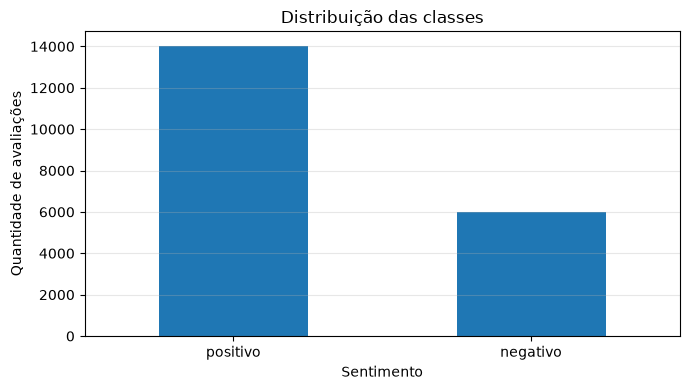

sentimento
positivo    70.1%
negativo    29.9%
Name: count, dtype: str


In [5]:
contagem = df["sentimento"].value_counts()

ax = contagem.plot(kind="bar", figsize=(7, 4))
ax.set_title("Distribuição das classes")
ax.set_xlabel("Sentimento")
ax.set_ylabel("Quantidade de avaliações")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print((contagem / contagem.sum() * 100).round(1).astype(str) + "%")

### Observando os textos

Leia alguns exemplos de cada classe. Antes de treinar um algoritmo, é importante entender que tipo de linguagem aparece nos dados e procurar possíveis problemas, como textos vazios ou avaliações que não expressam claramente uma opinião.

In [6]:
for classe in ["positivo", "negativo"]:
    print(f"\n--- Exemplos {classe.upper()} ---")
    exemplos = df.loc[df["sentimento"] == classe, "review_text"].head(3)
    for i, texto in enumerate(exemplos, start=1):
        print(f"{i}. {texto[:500]}")


--- Exemplos POSITIVO ---
1. Minha filha amou a boneca.  Qualidade do material é muito boa e ela é bem macia e flexivel.  Recomenda a todos.
2. Produto de qualidade, só poderia ter vindo um cabo VGA em vez do cabo Displayport. Fora isso não tenho do que reclamar! Super recomendo.
3. Sou do RJ O preço da cama esta bom..Estava quase comprando, mas qdo vi o valor absurdo do frete e o tempo enorme para entrega 38 dias desisti.

--- Exemplos NEGATIVO ---
1. O produto que me foi enviado é pirata , não condizente com o anúncio. A loja "BEST MIX" é parceira da Americanas.com e coleciona reclamações sobre diversos aspectos. É uma pena, a Americanas.com ser cúmplice desse tipo de "malandragem", mas diante do Brasil em que estamos vivendo; é totalmente compreensível  .
2. Recebi e fui testar umas 20 dias depois de recebido porque estava sem tempo e percebi que estava queimado, os queimadores não aquecem, agora só com o fabricante , mas fica a frustração!
3. Realizei a compra deste produto no dia

## 4. Divisão entre treinamento e teste

Separaremos os dados em:
- **80% para treinamento:** o modelo aprende os padrões;
- **20% para teste:** avaliamos o desempenho em textos que não foram usados no treinamento.

Usamos `stratify=y` para preservar aproximadamente a proporção entre sentimentos nos dois conjuntos. A divisão é feita antes de ajustar o vetorizador, evitando que o vocabulário e os pesos do TF-IDF sejam aprendidos a partir dos dados de teste.

In [7]:
X = df["review_text"].astype(str)
y = df["sentimento"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Treinamento: {len(X_train):,} textos")
print(f"Teste:       {len(X_test):,} textos")
print("\nDistribuição no treino:")
print(y_train.value_counts(normalize=True).round(3))
print("\nDistribuição no teste:")
print(y_test.value_counts(normalize=True).round(3))

Treinamento: 16,000 textos
Teste:       4,000 textos

Distribuição no treino:
sentimento
positivo    0.701
negativo    0.299
Name: proportion, dtype: float64

Distribuição no teste:
sentimento
positivo    0.701
negativo    0.299
Name: proportion, dtype: float64


## 5. Como transformar texto em números: TF-IDF

Algoritmos clássicos de aprendizado de máquina geralmente não recebem frases diretamente. Precisamos representá-las numericamente.

O **TF-IDF** (*Term Frequency–Inverse Document Frequency*) atribui pesos aos termos:
- **TF:** considera a frequência do termo no texto;
- **IDF:** reduz o peso de termos que aparecem em muitos documentos e, portanto, tendem a ser menos discriminativos.

Também usaremos `ngram_range=(1, 2)`: o modelo considera tanto palavras isoladas (*unigramas*) quanto pares de palavras consecutivas (*bigramas*). Isso pode ajudar a aprender expressões como “muito bom” ou “não gostei”.

O `Pipeline` encadeia a vetorização e o classificador. Quando chamamos `fit` no pipeline, o TF-IDF é ajustado somente no conjunto de treinamento.

In [8]:
vetorizador_demo = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
)

# Demonstração pequena para visualizar a representação numérica.
textos_demo = [
    "O produto é muito bom",
    "O produto não é bom",
    "Gostei muito do produto",
]

matriz_demo = vetorizador_demo.fit_transform(textos_demo)
termos_demo = vetorizador_demo.get_feature_names_out()

print("Formato da matriz TF-IDF:", matriz_demo.shape)
display(pd.DataFrame(
    matriz_demo.toarray(),
    columns=termos_demo,
    index=[f"Texto {i+1}" for i in range(len(textos_demo))]
).round(2))

Formato da matriz TF-IDF: (3, 3)


,bom,muito,produto
Texto 1,0.62,0.62,0.48
Texto 2,0.79,0.00,0.61
Texto 3,0.00,0.79,0.61


## 6. Construção e treinamento do classificador

Usaremos **Regressão Logística**, um algoritmo supervisionado comum em classificação de texto. Apesar do nome, neste caso ele é usado para prever categorias.

O modelo não entende o significado das palavras como uma pessoa. Ele aprende associações estatísticas entre os pesos dos termos e os rótulos `positivo` e `negativo` presentes nos exemplos.

In [11]:
modelo = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_features=30000,
            sublinear_tf=True,
        ),
    ),
    (
        "classificador",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
])

modelo.fit(X_train, y_train)
print("Treinamento concluído.")

Treinamento concluído.


## 7. Avaliação do modelo

Vamos avaliar o classificador no conjunto de teste, que ficou separado durante o treinamento.

- **Acurácia:** proporção total de previsões corretas.
- **Precisão:** entre as previsões de uma classe, quantas estavam corretas.
- **Revocação (recall):** entre os exemplos reais de uma classe, quantos foram encontrados.
- **F1-score:** média harmônica entre precisão e revocação.

Não escolha um modelo apenas pela acurácia: observe também as métricas por classe e a matriz de confusão.

In [12]:
y_pred = modelo.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro: {f1_score(y_test, y_pred, average='macro'):.3f}")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred, digits=3))

Acurácia: 0.926
F1 macro: 0.915

Relatório de classificação:
              precision    recall  f1-score   support

    negativo      0.832     0.945     0.885      1195
    positivo      0.975     0.919     0.946      2805

    accuracy                          0.926      4000
   macro avg      0.904     0.932     0.915      4000
weighted avg      0.932     0.926     0.928      4000



In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["negativo", "positivo"],
    cmap="Blues",
    values_format="d",
)
plt.title("Matriz de confusão — conjunto de teste")
plt.tight_layout()
plt.show()

## 8. Testando frases novas

Agora vamos usar o modelo em frases digitadas por nós. Pense nos resultados como previsões, não como verdades garantidas. Uma frase curta, irônica ou ambígua pode ser classificada incorretamente.

In [ ]:
novas_avaliacoes = [
    "Produto excelente, chegou antes do prazo e funciona muito bem.",
    "Péssima qualidade, parou de funcionar no primeiro dia.",
    "O produto é bom, mas a entrega demorou demais.",
    "Não gostei, esperava muito mais.",
    "Atendeu às minhas expectativas.",
    "Muito bonito e fácil de usar.",
]

previsoes = modelo.predict(novas_avaliacoes)

for texto, sentimento in zip(novas_avaliacoes, previsoes):
    print(f"Texto: {texto}")
    print(f"Sentimento previsto: {sentimento}")
    print("-" * 70)

## 9. Quais termos influenciam as previsões?

Na Regressão Logística binária, os coeficientes ajudam a observar quais termos estão associados a cada classe no conjunto de treinamento. Isso não significa que uma palavra tenha sempre o mesmo sentimento em qualquer contexto: por exemplo, a negação pode mudar completamente o sentido de uma frase.

In [ ]:
vet = modelo.named_steps["tfidf"]
clf = modelo.named_steps["classificador"]
termos = vet.get_feature_names_out()
coeficientes = clf.coef_[0]

# A ordem das classes pode variar conforme os rótulos; mostramos também as classes.
print("Classes do classificador:", clf.classes_)

indices_negativos = np.argsort(coeficientes)[:15]
indices_positivos = np.argsort(coeficientes)[-15:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(termos[indices_negativos][::-1], coeficientes[indices_negativos][::-1])
axes[0].set_title("Termos mais associados à primeira classe")
axes[0].set_xlabel("Coeficiente")

axes[1].barh(termos[indices_positivos][::-1], coeficientes[indices_positivos][::-1])
axes[1].set_title("Termos mais associados à segunda classe")
axes[1].set_xlabel("Coeficiente")

plt.tight_layout()
plt.show()

print("Observação: os coeficientes são relativos ao mapeamento de classes do modelo.")

## 10. Experimentos sugeridos

Modifique uma variável por vez e compare as métricas.

1. **Quantidade de dados:** altere `MAX_EXAMPLES` para `5_000`, `20_000` ou `50_000`. O que muda no desempenho e no tempo de treinamento?
2. **N-gramas:** troque `ngram_range=(1, 2)` por `(1, 1)`. A presença de pares de palavras ajuda?
3. **Vocabulário:** altere `max_features=30000` para `10000` ou `50000`. Como isso afeta o custo e o desempenho?
4. **Balanceamento:** experimente retirar `class_weight="balanced"`. O desempenho de cada classe muda?
5. **Casos difíceis:** crie frases com negação (“não é ruim”), ironia, erros de digitação ou elogios misturados com reclamações.

Lembre-se: depois de modificar os parâmetros do modelo ou a amostra, execute novamente as células necessárias desde a preparação dos dados até a avaliação.

## 11. Limitações e próximos passos

Este notebook usa um método clássico de PLN:
- TF-IDF representa textos com pesos de termos, mas não captura plenamente o significado e o contexto;
- a classificação depende dos rótulos criados a partir das notas, que nem sempre refletem perfeitamente o sentimento do texto;
- avaliações neutras foram removidas;
- os resultados dependem do domínio, do tamanho da amostra e da qualidade dos dados.

### Caminhos para continuar
- comparar com Naive Bayes ou SVM;
- testar pré-processamento com spaCy para português;
- comparar TF-IDF com embeddings de palavras;
- experimentar uma rede neural recorrente (LSTM/GRU);
- comparar com um Transformer pré-treinado para português, como o BERTimbau.

### Referência do dataset

Real, L., Oshiro, M. e Mafra, A. (2019). *B2W-Reviews01: an open product reviews corpus*. O dataset é disponibilizado sob licença **CC BY-NC-SA 4.0**; consulte a licença e as condições de uso no repositório antes de redistribuir os dados ou derivados.

- [Repositório B2W-Reviews01](https://github.com/americanas-tech/b2w-reviews01)
- [Licença Creative Commons BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/)